# 🔬 Notebook 01 — EDA & Nettoyage des Données

**Projet :** Prédiction de l'Attrition des Employés — Data Mining 2026/2027  
**Dataset :** `data/raw/Employee_Attrition_DataSet.csv` (10 000 lignes × 14 colonnes)  

---

## Plan du notebook

1. [Chargement des données](#1-chargement)
2. [Aperçu général](#2-apercu)
3. [Qualité des données](#3-qualite) — NaN, doublons, colonnes constantes
4. [Détection des valeurs aberrantes (IQR)](#4-outliers)
5. [Pipeline de nettoyage](#5-nettoyage)
6. [Analyse univariée](#6-univariee)
7. [Analyse bivariée — Variables × Attrition](#7-bivariee)
8. [Corrélations & déséquilibre de classes](#8-correlations)
9. [Export du dataset nettoyé](#9-export)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

# Project root on path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    load_raw_data, NUMERICAL_FEATURES, CATEGORICAL_FEATURES, TARGET, ID_COL
)
from src.statistics import (
    compute_descriptive_stats, chi2_test, ttest_by_group, correlation_matrix
)

# ── Style ────────────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13, 'axes.labelsize': 11})

INDIGO  = '#4F46E5'
CYAN    = '#06B6D4'
GREEN   = '#10B981'
RED     = '#EF4444'
AMBER   = '#F59E0B'
PALETTE = [GREEN, RED]   # No=vert, Yes=rouge

print('✅ Imports OK — Projet :', PROJECT_ROOT.name)

✅ Imports OK — Projet : data mining


---
## 1. Chargement des données <a id='1-chargement'></a>

In [2]:
df_raw = load_raw_data()
print(f'Dimensions : {df_raw.shape[0]:,} lignes × {df_raw.shape[1]} colonnes')
df_raw.head()

Dimensions : 10,000 lignes × 14 colonnes


,EmployeeID,Age,Department,JobLevel,YearsAtCompany,MonthlyIncome,JobSatisfaction,WorkLifeBalance,OverTime,DistanceFromHome,PromotionLast5Years,PerformanceRating,TrainingHoursLastYear,Attrition
0,EMP0000,42,Sales,3,9,9866,4,1,No,24.5,Yes,4,19,No
1,EMP0001,36,Sales,3,7,8958,3,3,No,10.0,No,2,13,No
2,EMP0002,44,Sales,4,16,11716,4,3,No,4.0,No,4,13,No
3,EMP0003,53,Finance,4,30,17061,5,3,No,7.1,No,3,20,No
4,EMP0004,35,HR,2,4,5738,2,3,No,8.4,No,2,15,No


In [3]:
print('Types de colonnes :')
print(df_raw.dtypes.value_counts())
print(f'\nMémoire utilisée : {df_raw.memory_usage(deep=True).sum() / 1024:.1f} Ko')

Types de colonnes :
int64      8
object     5
float64    1
Name: count, dtype: int64

Mémoire utilisée : 3297.0 Ko


---
## 2. Aperçu général <a id='2-apercu'></a>

In [4]:
# Types et cardinalités
dtype_df = pd.DataFrame({
    'Type'           : df_raw.dtypes.astype(str),
    'Valeurs uniques': df_raw.nunique(),
    'Exemple'        : df_raw.iloc[0],
})
print(dtype_df.to_string())

                          Type  Valeurs uniques  Exemple
EmployeeID              object            10000  EMP0000
Age                      int64               39       42
Department              object                7    Sales
JobLevel                 int64                5        3
YearsAtCompany           int64               36        9
MonthlyIncome            int64             6784     9866
JobSatisfaction          int64                5        4
WorkLifeBalance          int64                4        1
OverTime                object                2       No
DistanceFromHome       float64              381     24.5
PromotionLast5Years     object                2      Yes
PerformanceRating        int64                4        4
TrainingHoursLastYear    int64               30       19
Attrition               object                2       No


In [5]:
# Statistiques descriptives — variables numériques
desc = compute_descriptive_stats(df_raw, NUMERICAL_FEATURES).round(2)
print('Statistiques descriptives :')
desc

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
Age,10000.0,37.69,9.38,22.0,31.0,37.0,44.0,60.0
JobLevel,10000.0,2.38,1.14,1.0,1.0,2.0,3.0,5.0
YearsAtCompany,10000.0,7.79,7.14,0.0,2.0,6.0,12.0,35.0
MonthlyIncome,10000.0,8967.92,3500.75,3000.0,6043.5,8670.0,11484.0,21410.0
JobSatisfaction,10000.0,3.36,1.06,1.0,3.0,3.0,4.0,5.0
WorkLifeBalance,10000.0,2.76,0.89,1.0,2.0,3.0,3.0,4.0
DistanceFromHome,10000.0,9.91,6.97,1.0,4.7,8.3,13.4,50.0
PerformanceRating,10000.0,2.60,0.74,1.0,2.0,3.0,3.0,4.0
TrainingHoursLastYear,10000.0,14.99,3.89,2.0,12.0,15.0,18.0,31.0


---
## 3. Qualité des données <a id='3-qualite'></a>

In [6]:
# --- 3.1 Valeurs manquantes ---
missing = df_raw.isna().sum().rename('NaN').to_frame()
missing['%'] = (missing['NaN'] / len(df_raw) * 100).round(2)
missing = missing[missing['NaN'] > 0].sort_values('NaN', ascending=False)

if missing.empty:
    print('✅ Aucune valeur manquante détectée.')
else:
    print(f'⚠️  {missing["NaN"].sum()} valeur(s) manquante(s) :')
    print(missing)

✅ Aucune valeur manquante détectée.


In [7]:
# --- 3.2 Doublons ---
n_dup = df_raw.duplicated().sum()
print(f'Doublons : {n_dup}')
if n_dup > 0:
    print(df_raw[df_raw.duplicated()].head())

Doublons : 0


In [8]:
# --- 3.3 Colonnes constantes & colonnes identifiant ---
const_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
id_cols    = [c for c in df_raw.columns if 'id' in c.lower()]
print(f'Colonnes constantes : {const_cols or "aucune"}')
print(f'Colonnes identifiant : {id_cols}')

Colonnes constantes : aucune
Colonnes identifiant : ['EmployeeID']


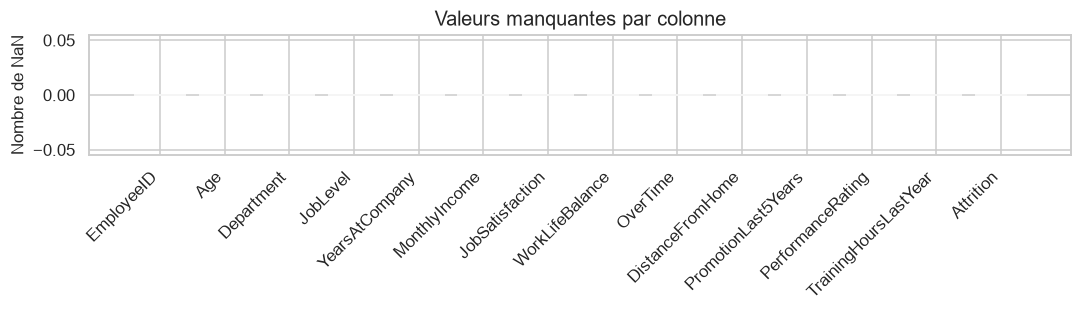

(0 NaN = dataset déjà propre)


In [9]:
# --- 3.4 Visualisation des valeurs manquantes ---
nan_all = df_raw.isna().sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(nan_all.index, nan_all.values, color=INDIGO)
ax.set_title('Valeurs manquantes par colonne')
ax.set_ylabel('Nombre de NaN')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
print('(0 NaN = dataset déjà propre)')

---
## 4. Détection des valeurs aberrantes (méthode IQR × 1.5) <a id='4-outliers'></a>

In [10]:
def detect_outliers_iqr(df, columns):
    """Retourne un tableau récapitulatif des outliers IQR par colonne."""
    rows = []
    for col in columns:
        if col not in df.columns:
            continue
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (df[col] < lower) | (df[col] > upper)
        n = int(mask.sum())
        rows.append({
            'Variable'      : col,
            'Q1'            : round(q1, 2),
            'Q3'            : round(q3, 2),
            'IQR'           : round(iqr, 2),
            'Borne inf.'    : round(lower, 2),
            'Borne sup.'    : round(upper, 2),
            'Nb aberrants'  : n,
            '% aberrants'   : round(100 * n / max(len(df), 1), 2),
        })
    return pd.DataFrame(rows)

outlier_df = detect_outliers_iqr(df_raw, NUMERICAL_FEATURES)
outlier_df

,Variable,Q1,Q3,IQR,Borne inf.,Borne sup.,Nb aberrants,% aberrants
0,Age,31.0,44.0,13.0,11.50,63.50,0,0.00
1,JobLevel,1.0,3.0,2.0,-2.00,6.00,0,0.00
2,YearsAtCompany,2.0,12.0,10.0,-13.00,27.00,142,1.42
3,MonthlyIncome,6043.5,11484.0,5440.5,-2117.25,19644.75,12,0.12
4,JobSatisfaction,3.0,4.0,1.0,1.50,5.50,500,5.00
5,WorkLifeBalance,2.0,3.0,1.0,0.50,4.50,0,0.00
6,DistanceFromHome,4.7,13.4,8.7,-8.35,26.45,306,3.06
7,PerformanceRating,2.0,3.0,1.0,0.50,4.50,0,0.00
8,TrainingHoursLastYear,12.0,18.0,6.0,3.00,27.00,15,0.15


C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\2549089416.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


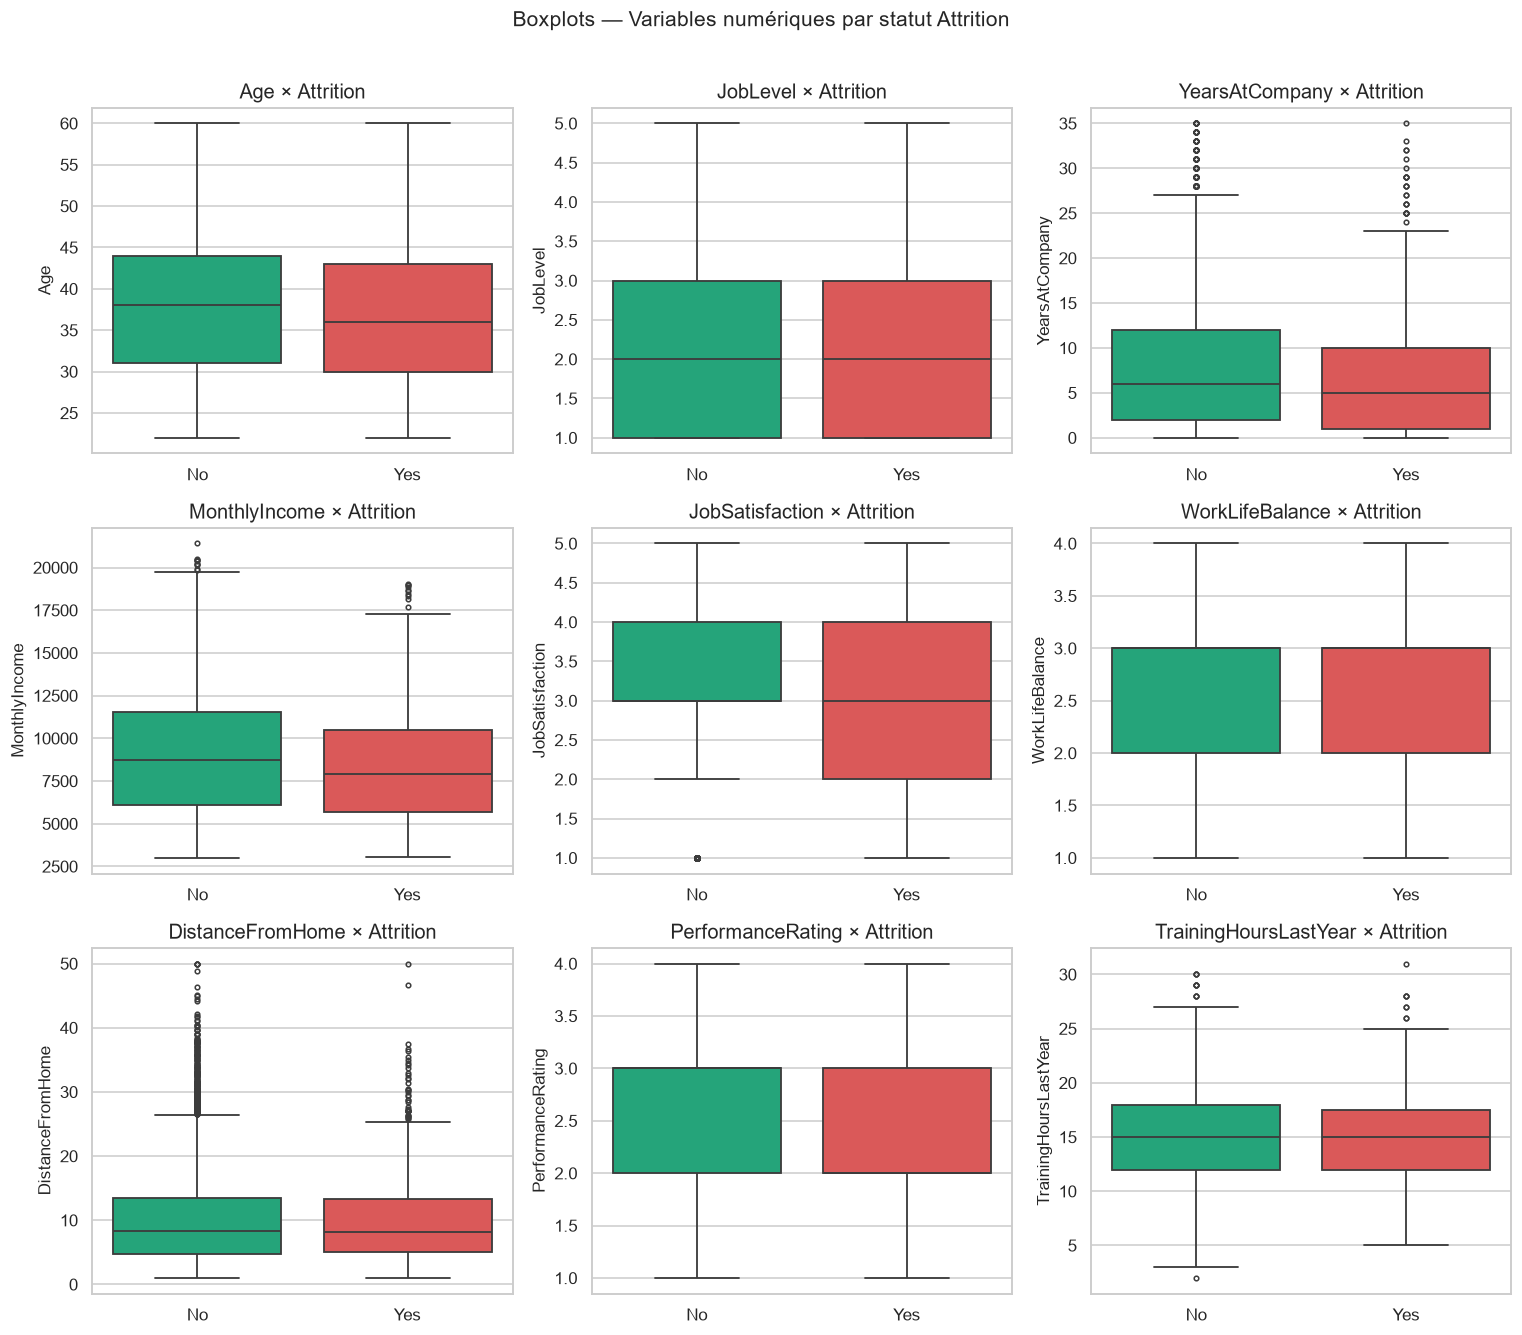

In [11]:
# Boxplots des variables numériques colorés par Attrition
n_cols = 3
n_rows = -(-len(NUMERICAL_FEATURES) // n_cols)  # ceil division
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(NUMERICAL_FEATURES):
    sns.boxplot(
        data=df_raw, x=TARGET, y=col,
        palette={'No': GREEN, 'Yes': RED},
        ax=axes[i], linewidth=1.2, fliersize=3
    )
    axes[i].set_title(f'{col} × Attrition')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Boxplots — Variables numériques par statut Attrition', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

---
## 5. Pipeline de nettoyage <a id='5-nettoyage'></a>

Étapes appliquées :
1. Suppression de la colonne identifiant (`EmployeeID`)
2. Suppression des doublons
3. Suppression des colonnes constantes
4. Imputation des valeurs manquantes (médiane pour le numérique, mode pour le catégoriel)
5. Écrêtage des outliers (IQR × 1.5)
6. Correction des types (object → category)

In [12]:
def clean_data(df: pd.DataFrame):
    """
    Nettoie le dataset brut.
    Retourne (df_clean, report) où report est un dict de métriques avant/après.
    """
    report = {
        'rows_before': len(df),
        'cols_before': len(df.columns),
        'nan_before' : int(df.isna().sum().sum()),
        'dup_before' : int(df.duplicated().sum()),
    }
    cleaned = df.copy()

    # Étape 1 — Supprimer les colonnes identifiant
    id_cols_present = [c for c in [ID_COL] if c in cleaned.columns]
    cleaned.drop(columns=id_cols_present, inplace=True)
    report['dropped_id'] = id_cols_present

    # Étape 2 — Supprimer les doublons
    n_before = len(cleaned)
    cleaned.drop_duplicates(inplace=True)
    report['dup_removed'] = n_before - len(cleaned)

    # Étape 3 — Supprimer les colonnes constantes
    const = [c for c in cleaned.columns if cleaned[c].nunique(dropna=False) <= 1]
    cleaned.drop(columns=const, inplace=True)
    report['const_removed'] = const

    # Étape 4 — Imputer les NaN
    total_nan = int(cleaned.isna().sum().sum())
    for col in cleaned.columns:
        if cleaned[col].isna().sum() == 0:
            continue
        if cleaned[col].dtype in [np.float64, np.int64, float, int]:
            cleaned[col].fillna(cleaned[col].median(), inplace=True)
        else:
            mode_val = cleaned[col].mode()
            if len(mode_val):
                cleaned[col].fillna(mode_val[0], inplace=True)
    report['nan_imputed'] = total_nan

    # Étape 5 — Écrêtage des outliers (IQR × 1.5)
    num_cols = [c for c in NUMERICAL_FEATURES if c in cleaned.columns]
    capped = {}
    for col in num_cols:
        q1, q3 = cleaned[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((cleaned[col] < lower) | (cleaned[col] > upper)).sum())
        if n_out:
            cleaned[col] = cleaned[col].clip(lower, upper)
            capped[col] = n_out
    report['outliers_capped'] = capped
    report['total_capped']    = sum(capped.values())

    # Étape 6 — Corriger les types
    cat_cols = [c for c in cleaned.columns if cleaned[c].dtype == object]
    for col in cat_cols:
        cleaned[col] = cleaned[col].astype('category')
    report['cat_encoded'] = cat_cols

    report['rows_after'] = len(cleaned)
    report['cols_after'] = len(cleaned.columns)
    report['nan_after']  = int(cleaned.isna().sum().sum())

    return cleaned, report


df_clean, report = clean_data(df_raw)
print('Pipeline de nettoyage terminé ✅')
for k, v in report.items():
    print(f'  {k:25s}: {v}')

Pipeline de nettoyage terminé ✅
  rows_before              : 10000
  cols_before              : 14
  nan_before               : 0
  dup_before               : 0
  dropped_id               : ['EmployeeID']
  dup_removed              : 0
  const_removed            : []
  nan_imputed              : 0
  outliers_capped          : {'YearsAtCompany': 142, 'MonthlyIncome': 12, 'JobSatisfaction': 500, 'DistanceFromHome': 306, 'TrainingHoursLastYear': 15}
  total_capped             : 975
  cat_encoded              : ['Department', 'OverTime', 'PromotionLast5Years', 'Attrition']
  rows_after               : 10000
  cols_after               : 13
  nan_after                : 0



━━━━ Comparaison Avant / Après ━━━━
Métrique  Avant  Après  Δ
  Lignes  10000  10000  0
Colonnes     14     13 -1
     NaN      0      0  0


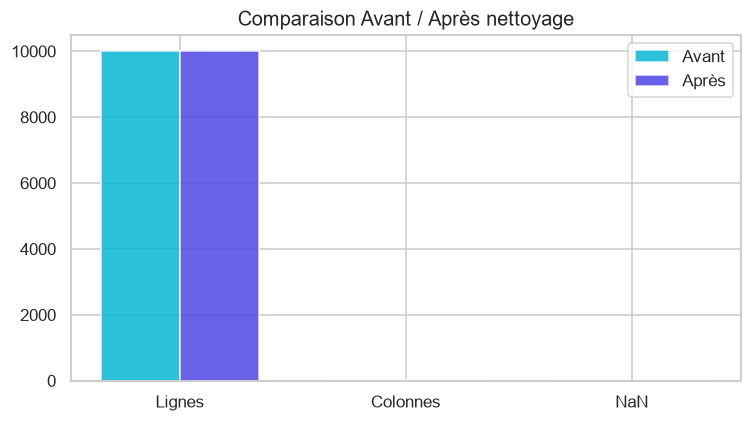

In [13]:
# Tableau comparatif Avant / Après
comparison = pd.DataFrame({
    'Métrique'  : ['Lignes', 'Colonnes', 'NaN'],
    'Avant'     : [report['rows_before'], report['cols_before'], report['nan_before']],
    'Après'     : [report['rows_after'],  report['cols_after'],  report['nan_after']],
})
comparison['Δ'] = comparison['Après'] - comparison['Avant']

print('\n━━━━ Comparaison Avant / Après ━━━━')
print(comparison.to_string(index=False))

# Graphique
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(comparison))
w = 0.35
ax.bar(x - w/2, comparison['Avant'], w, label='Avant', color=CYAN,   alpha=0.85)
ax.bar(x + w/2, comparison['Après'], w, label='Après', color=INDIGO, alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(comparison['Métrique'])
ax.set_title('Comparaison Avant / Après nettoyage')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
print('Aperçu du dataset nettoyé :')
df_clean.head()

Aperçu du dataset nettoyé :


,Age,Department,JobLevel,YearsAtCompany,MonthlyIncome,JobSatisfaction,WorkLifeBalance,OverTime,DistanceFromHome,PromotionLast5Years,PerformanceRating,TrainingHoursLastYear,Attrition
0,42,Sales,3,9,9866.0,4.0,1,No,24.5,Yes,4,19,No
1,36,Sales,3,7,8958.0,3.0,3,No,10.0,No,2,13,No
2,44,Sales,4,16,11716.0,4.0,3,No,4.0,No,4,13,No
3,53,Finance,4,27,17061.0,5.0,3,No,7.1,No,3,20,No
4,35,HR,2,4,5738.0,2.0,3,No,8.4,No,2,15,No


---
## 6. Analyse univariée <a id='6-univariee'></a>

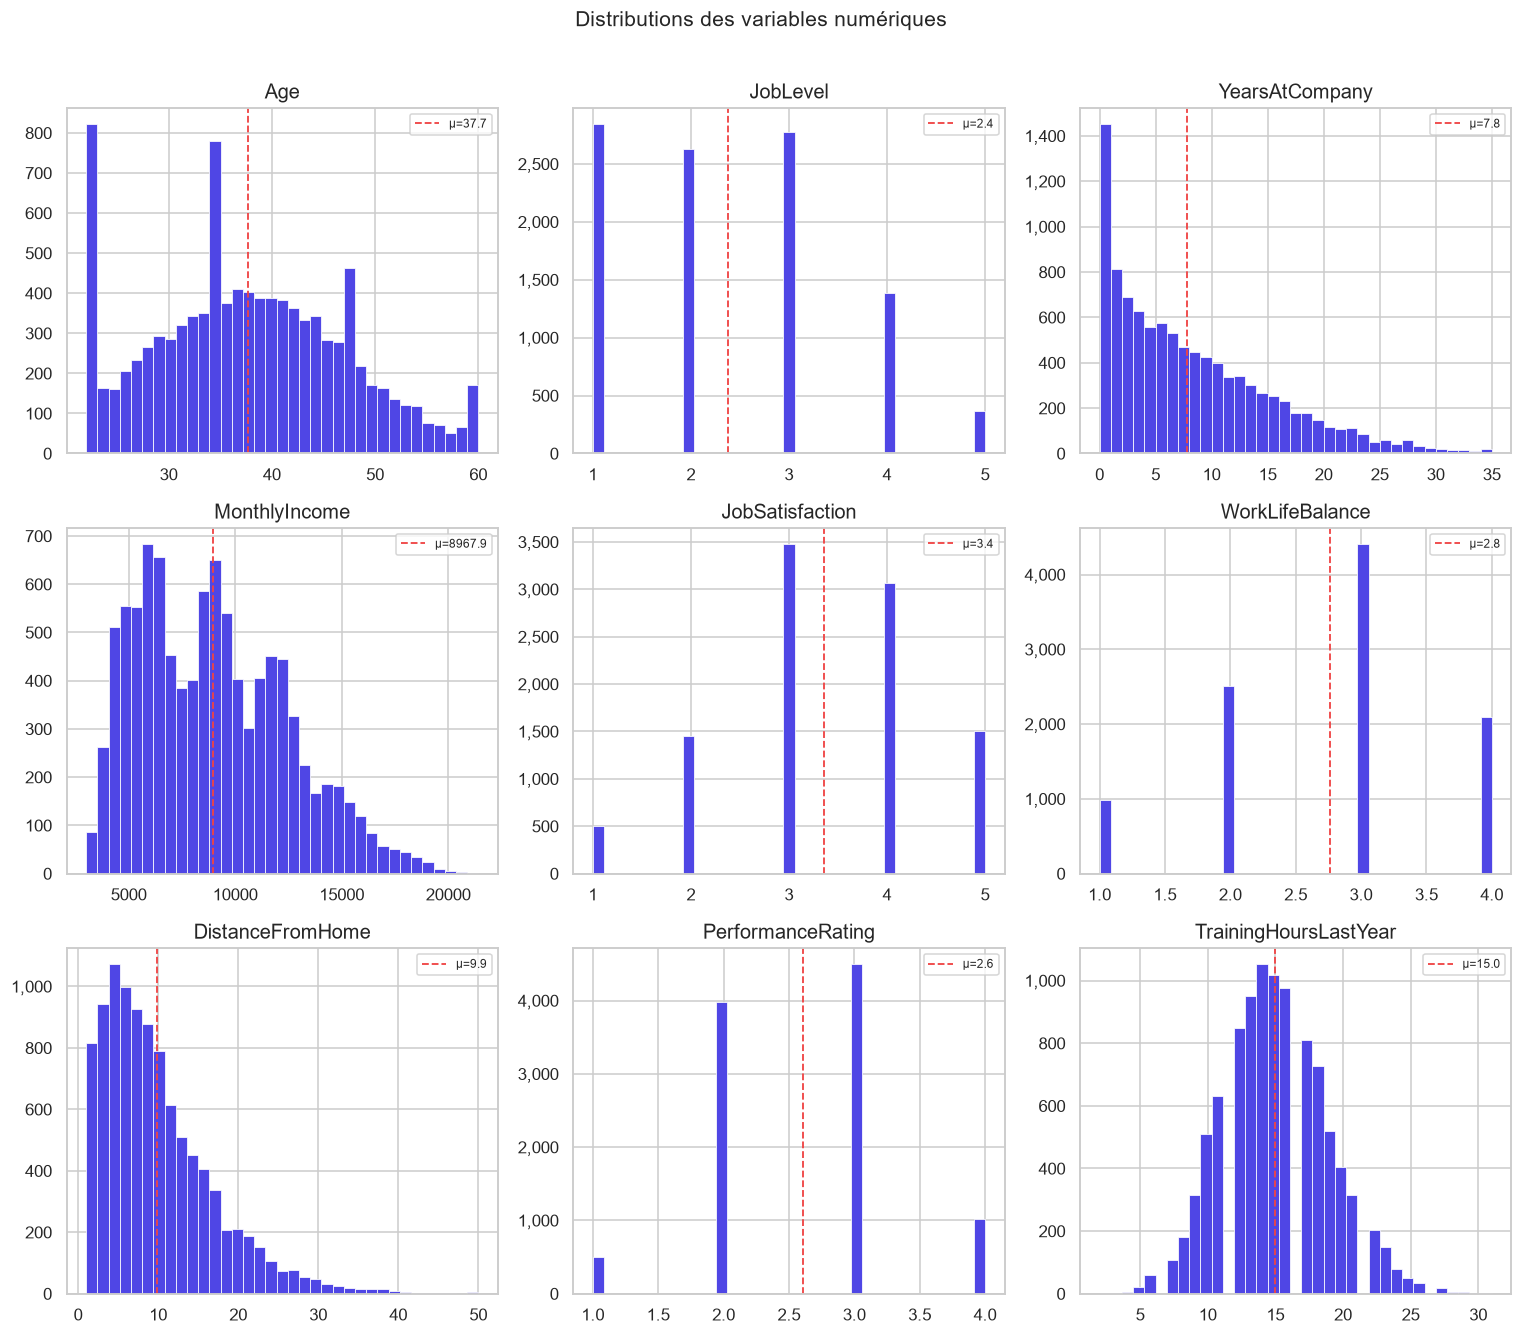

In [15]:
# Histogrammes — Variables numériques
n_cols = 3
n_rows = -(-len(NUMERICAL_FEATURES) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(NUMERICAL_FEATURES):
    axes[i].hist(df_raw[col].dropna(), bins=35, color=INDIGO, edgecolor='white', linewidth=0.5)
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('')
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v):,}'))
    mu, sigma = df_raw[col].mean(), df_raw[col].std()
    axes[i].axvline(mu, color=RED, linestyle='--', linewidth=1.2, label=f'μ={mu:.1f}')
    axes[i].legend(fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distributions des variables numériques', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [16]:
# Statistiques de forme (skewness, kurtosis)
shape_stats = pd.DataFrame({
    'Moyenne'  : df_raw[NUMERICAL_FEATURES].mean().round(2),
    'Médiane'  : df_raw[NUMERICAL_FEATURES].median().round(2),
    'Std'      : df_raw[NUMERICAL_FEATURES].std().round(2),
    'Skewness' : df_raw[NUMERICAL_FEATURES].skew().round(3),
    'Kurtosis' : df_raw[NUMERICAL_FEATURES].kurtosis().round(3),
})
shape_stats

,Moyenne,Médiane,Std,Skewness,Kurtosis
Age,37.69,37.0,9.38,0.198,-0.594
JobLevel,2.38,2.0,1.14,0.371,-0.783
YearsAtCompany,7.79,6.0,7.14,1.027,0.595
MonthlyIncome,8967.92,8670.0,3500.75,0.540,-0.366
JobSatisfaction,3.36,3.0,1.06,-0.253,-0.465
WorkLifeBalance,2.76,3.0,0.89,-0.343,-0.601
DistanceFromHome,9.91,8.3,6.97,1.345,2.398
PerformanceRating,2.60,3.0,0.74,0.028,-0.349
TrainingHoursLastYear,14.99,15.0,3.89,0.260,0.058


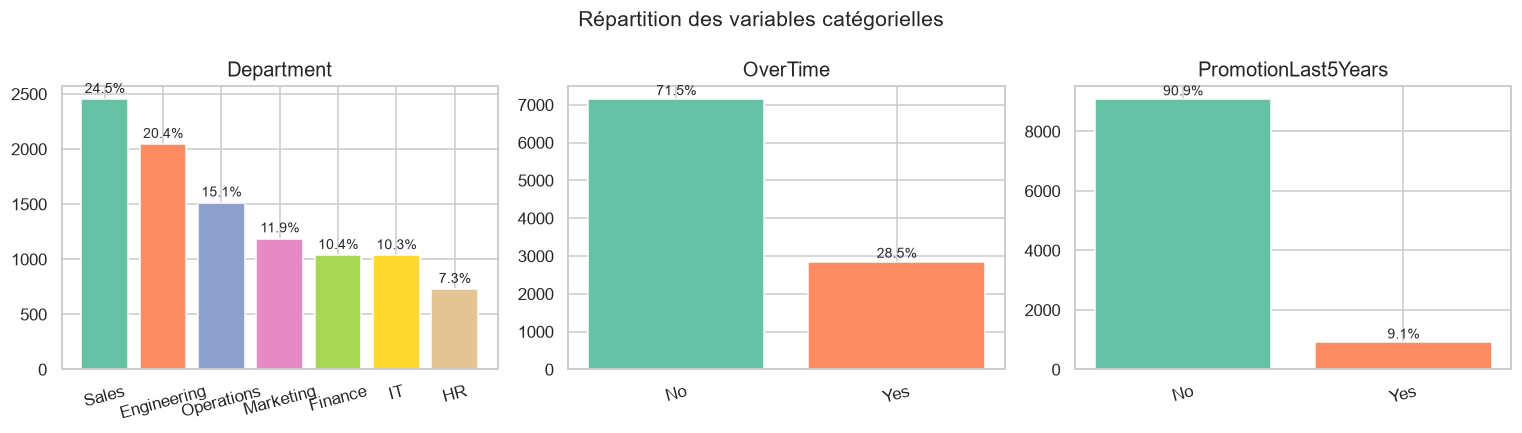

In [17]:
# Barres — Variables catégorielles
fig, axes = plt.subplots(1, len(CATEGORICAL_FEATURES), figsize=(14, 4))
palette = sns.color_palette('Set2', 10)

for i, col in enumerate(CATEGORICAL_FEATURES):
    vc = df_raw[col].value_counts()
    axes[i].bar(vc.index.astype(str), vc.values,
                color=palette[:len(vc)], edgecolor='white')
    axes[i].set_title(f'{col}')
    for bar, val in zip(axes[i].patches, vc.values):
        pct = val / len(df_raw) * 100
        axes[i].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
                     f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)
    axes[i].tick_params(axis='x', rotation=15)

fig.suptitle('Répartition des variables catégorielles', fontsize=14)
plt.tight_layout()
plt.show()

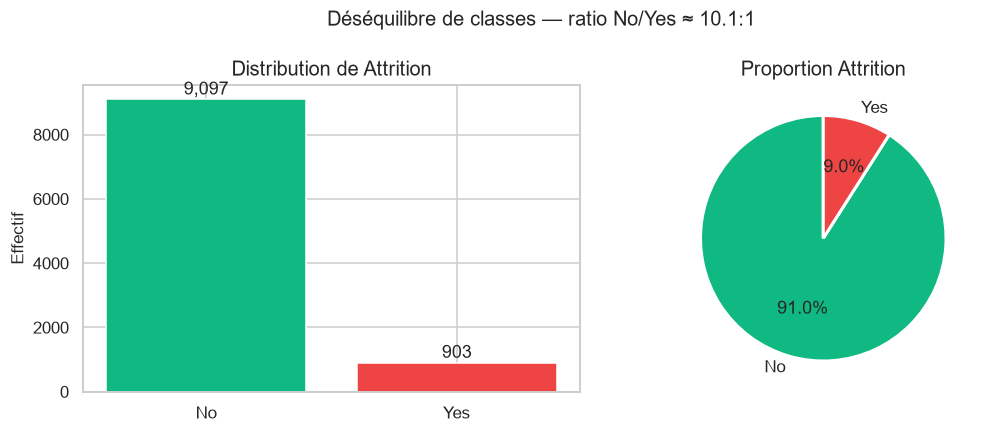

⚠️ Dataset fortement déséquilibré : techniques SMOTE / class_weight recommandées.


In [18]:
# Répartition de la variable cible
vc_target = df_raw[TARGET].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(vc_target.index, vc_target.values,
            color=[GREEN, RED], edgecolor='white')
axes[0].set_title(f'Distribution de {TARGET}')
axes[0].set_ylabel('Effectif')
for bar, val in zip(axes[0].patches, vc_target.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
                 f'{val:,}', ha='center', va='bottom')

axes[1].pie(vc_target.values, labels=vc_target.index,
            autopct='%1.1f%%', colors=[GREEN, RED],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title(f'Proportion {TARGET}')

ratio = vc_target.get('No', 0) / max(vc_target.get('Yes', 1), 1)
fig.suptitle(f'Déséquilibre de classes — ratio No/Yes ≈ {ratio:.1f}:1', fontsize=13)
plt.tight_layout()
plt.show()
print('⚠️ Dataset fortement déséquilibré : techniques SMOTE / class_weight recommandées.')

---
## 7. Analyse bivariée — Variables × Attrition <a id='7-bivariee'></a>

C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `leg

C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `leg

C:\Users\PC\AppData\Local\Temp\ipykernel_24156\569995647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


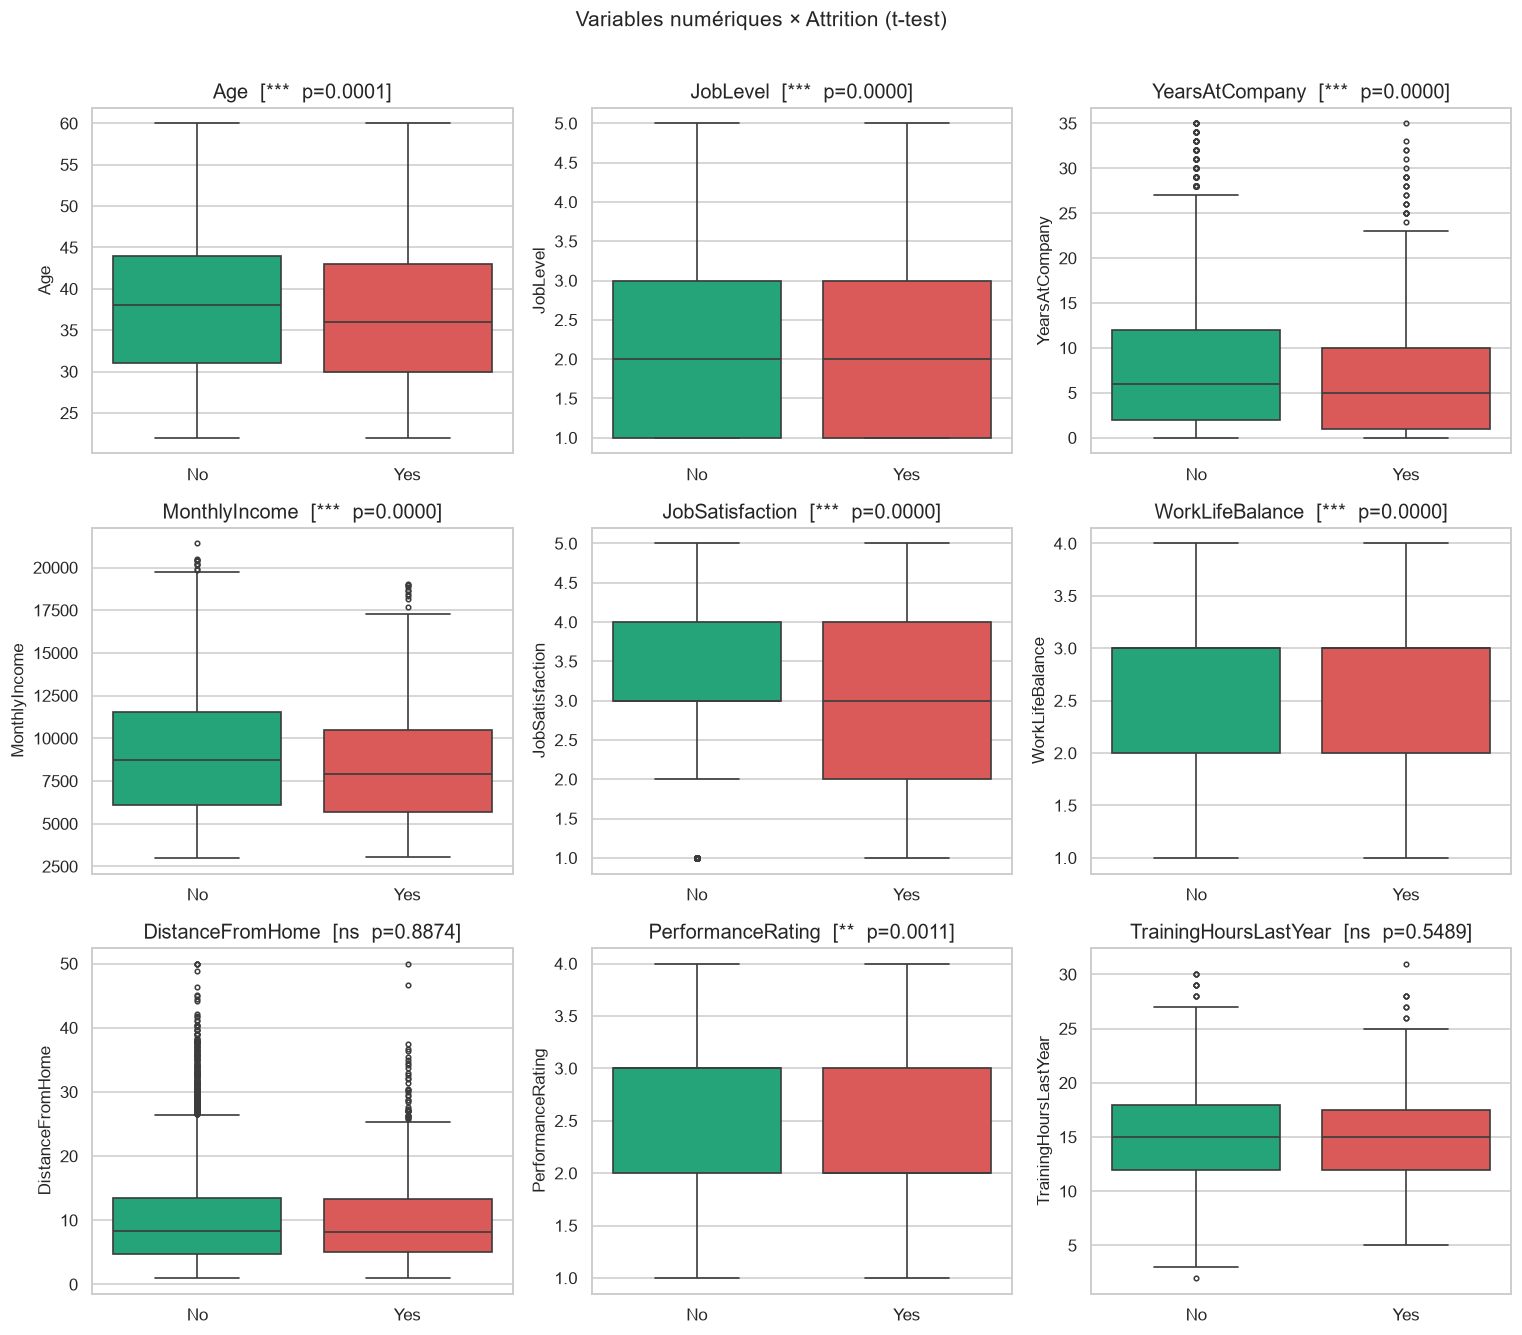


━━━━ Résultats t-tests ━━━━


,Variable,t_statistic,p_value,significant
0,Age,3.8772,0.000106,True
1,JobLevel,6.4897,0.000000,True
2,YearsAtCompany,5.7490,0.000000,True
3,MonthlyIncome,5.8952,0.000000,True
4,JobSatisfaction,8.6886,0.000000,True
5,WorkLifeBalance,7.1928,0.000000,True
6,DistanceFromHome,0.1416,0.887435,False
7,PerformanceRating,3.2751,0.001060,True
8,TrainingHoursLastYear,0.5994,0.548897,False


In [19]:
# 7.1 Variables numériques × Attrition — Boxplots + t-tests
results_ttest = []

n_rows = -(-len(NUMERICAL_FEATURES) // 3)
fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(NUMERICAL_FEATURES):
    res = ttest_by_group(df_raw, col, TARGET)
    results_ttest.append({'Variable': col, **res})

    sns.boxplot(
        data=df_raw, x=TARGET, y=col,
        palette={'No': GREEN, 'Yes': RED},
        ax=axes[i], linewidth=1.1, fliersize=3
    )
    sig_star = '***' if res['p_value'] < 0.001 else ('**' if res['p_value'] < 0.01
               else ('*' if res['p_value'] < 0.05 else 'ns'))
    axes[i].set_title(f'{col}  [{sig_star}  p={res["p_value"]:.4f}]')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Variables numériques × Attrition (t-test)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

print('\n━━━━ Résultats t-tests ━━━━')
pd.DataFrame(results_ttest)

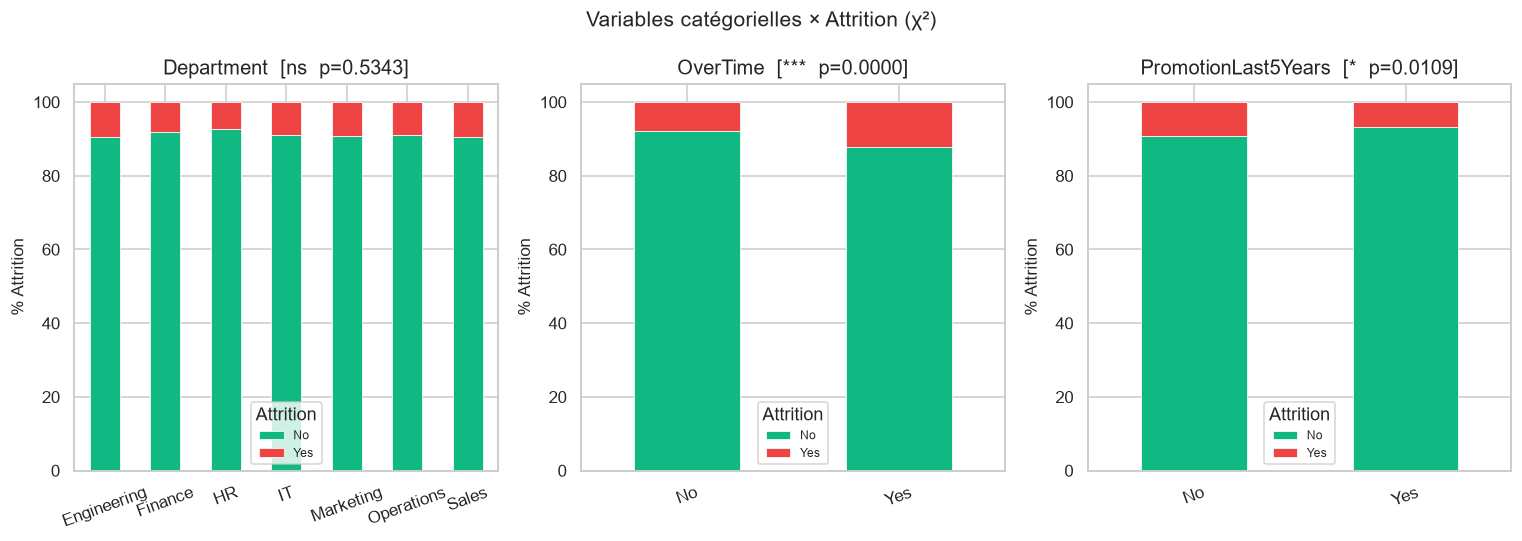


━━━━ Résultats tests χ² ━━━━


,Variable,chi2,p_value,dof,significant
0,Department,5.0745,0.534292,6,False
1,OverTime,47.5804,0.000000,1,True
2,PromotionLast5Years,6.4856,0.010875,1,True


In [20]:
# 7.2 Variables catégorielles × Attrition — Barres empilées + χ²
results_chi2 = []

fig, axes = plt.subplots(1, len(CATEGORICAL_FEATURES), figsize=(14, 5))

for i, col in enumerate(CATEGORICAL_FEATURES):
    res = chi2_test(df_raw, col, TARGET)
    results_chi2.append({'Variable': col, **res})

    cross_pct = pd.crosstab(df_raw[col], df_raw[TARGET], normalize='index') * 100
    cross_pct[['No', 'Yes']].plot(
        kind='bar', stacked=True,
        color=[GREEN, RED],
        ax=axes[i], edgecolor='white', linewidth=0.5
    )
    sig_star = '***' if res['p_value'] < 0.001 else ('**' if res['p_value'] < 0.01
               else ('*' if res['p_value'] < 0.05 else 'ns'))
    axes[i].set_title(f'{col}  [{sig_star}  p={res["p_value"]:.4f}]')
    axes[i].set_ylabel('% Attrition')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=20)
    axes[i].legend(title='Attrition', fontsize=8)

fig.suptitle('Variables catégorielles × Attrition (χ²)', fontsize=14)
plt.tight_layout()
plt.show()

print('\n━━━━ Résultats tests χ² ━━━━')
pd.DataFrame(results_chi2)

In [21]:
# 7.3 Taux de démission par modalité catégorielle
print('\n━━━━ Taux d\'attrition par modalité ━━━━')
for col in CATEGORICAL_FEATURES:
    rate = df_raw.groupby(col)[TARGET].apply(lambda x: (x == 'Yes').mean() * 100).round(1)
    rate.name = 'Taux attrition (%)'
    print(f'\n{col} :')
    print(rate.to_string())


━━━━ Taux d'attrition par modalité ━━━━

Department :
Department
Engineering    9.6
Finance        8.2
HR             7.3
IT             9.0
Marketing      9.1
Operations     8.9
Sales          9.5

OverTime :
OverTime
No      7.8
Yes    12.2

PromotionLast5Years :
PromotionLast5Years
No     9.3
Yes    6.7


---
## 8. Corrélations & déséquilibre de classes <a id='8-correlations'></a>

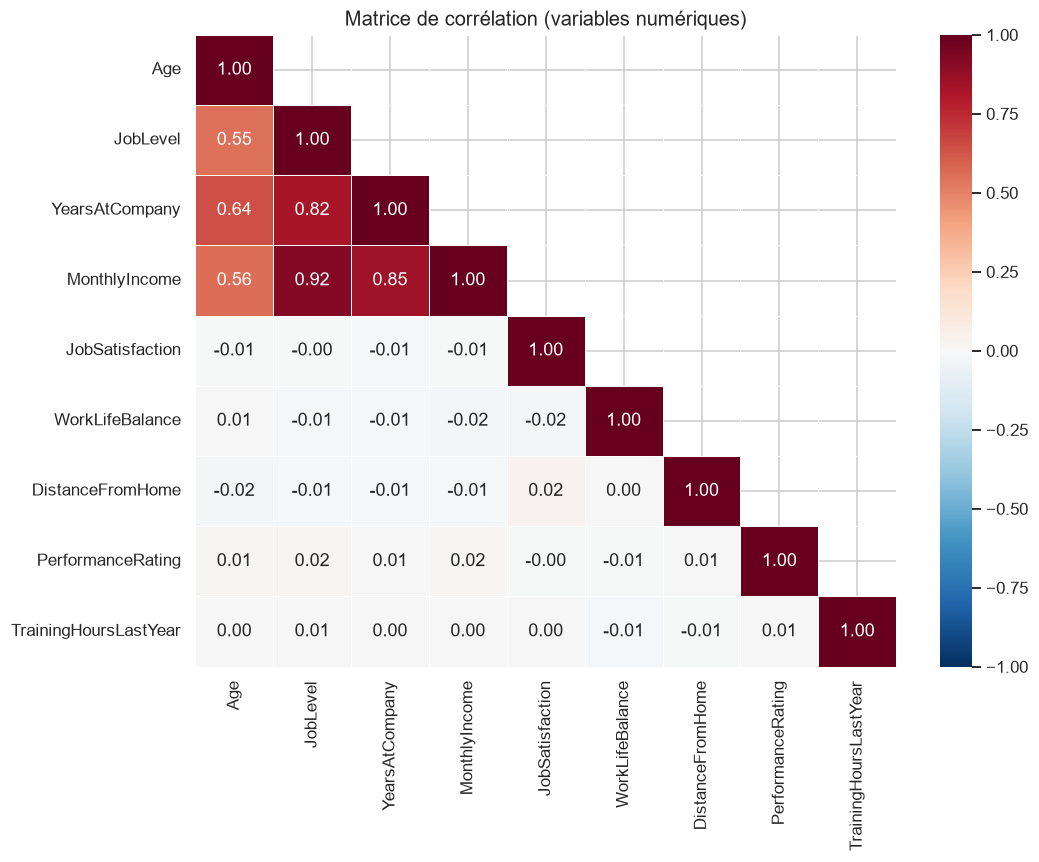

In [22]:
# 8.1 Heatmap de corrélation
corr = correlation_matrix(df_raw, NUMERICAL_FEATURES)

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='RdBu_r',
    vmin=-1, vmax=1, center=0,
    linewidths=0.5, ax=ax, mask=mask
)
ax.set_title('Matrice de corrélation (variables numériques)', fontsize=13)
plt.tight_layout()
plt.show()

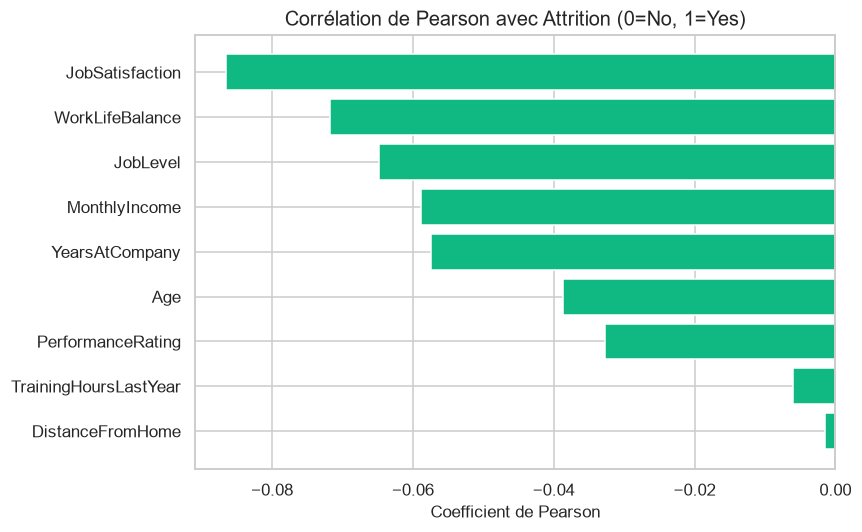


Top corrélations avec Attrition :
JobSatisfaction         -0.0866
WorkLifeBalance         -0.0717
JobLevel                -0.0648
MonthlyIncome           -0.0589
YearsAtCompany          -0.0574
Age                     -0.0387
PerformanceRating       -0.0327
TrainingHoursLastYear   -0.0060
DistanceFromHome        -0.0014


In [23]:
# 8.2 Corrélation avec la cible (Attrition encodée 0/1)
df_corr = df_raw.copy()
df_corr['Attrition_num'] = (df_corr[TARGET] == 'Yes').astype(int)

corr_target = (
    df_corr[NUMERICAL_FEATURES + ['Attrition_num']]
    .corr()['Attrition_num']
    .drop('Attrition_num')
    .sort_values(key=abs, ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 5))
colors = [RED if v > 0 else GREEN for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors, edgecolor='white')
ax.axvline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_title('Corrélation de Pearson avec Attrition (0=No, 1=Yes)')
ax.set_xlabel('Coefficient de Pearson')
plt.tight_layout()
plt.show()

print('\nTop corrélations avec Attrition :')
print(corr_target.sort_values(key=abs, ascending=False).round(4).to_string())

---
## 9. Export du dataset nettoyé <a id='9-export'></a>

In [24]:
# Convertir les catégories en str pour l'export CSV
df_export = df_clean.copy()
for col in df_export.select_dtypes('category').columns:
    df_export[col] = df_export[col].astype(str)

output_path = PROJECT_ROOT / 'data' / 'processed' / 'Employee_Attrition_Cleaned.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
df_export.to_csv(output_path, index=False)

print(f'✅ Dataset nettoyé exporté vers :')
print(f'   {output_path}')
print(f'   {df_export.shape[0]:,} lignes × {df_export.shape[1]} colonnes')
print(f'   NaN restants : {df_export.isna().sum().sum()}')
df_export.head()

✅ Dataset nettoyé exporté vers :
   E:\EMP\1 SIAD\DATA MINING\data mining\data\processed\Employee_Attrition_Cleaned.csv
   10,000 lignes × 13 colonnes
   NaN restants : 0


,Age,Department,JobLevel,YearsAtCompany,MonthlyIncome,JobSatisfaction,WorkLifeBalance,OverTime,DistanceFromHome,PromotionLast5Years,PerformanceRating,TrainingHoursLastYear,Attrition
0,42,Sales,3,9,9866.0,4.0,1,No,24.5,Yes,4,19,No
1,36,Sales,3,7,8958.0,3.0,3,No,10.0,No,2,13,No
2,44,Sales,4,16,11716.0,4.0,3,No,4.0,No,4,13,No
3,53,Finance,4,27,17061.0,5.0,3,No,7.1,No,3,20,No
4,35,HR,2,4,5738.0,2.0,3,No,8.4,No,2,15,No


---
## ✅ Résumé

| Étape | Résultat |
|---|---|
| Valeurs manquantes | Aucune (dataset synthétique propre) |
| Doublons supprimés | Voir `report['dup_removed']` |
| Colonne ID supprimée | `EmployeeID` |
| Outliers écrêtés | Voir `report['outliers_capped']` |
| Dataset exporté | `data/processed/Employee_Attrition_Cleaned.csv` |

> ➡️ **Suite :** `02_statistical_analysis.ipynb` — Tests d'hypothèses approfondis